In [1]:
# === Google Colab 自動環境セットアップ ===
# Google Colab で実行する場合は、以下のセルを実行してリポジトリのクローンと環境構築を行ってください。
# ローカル環境で実行する場合は、このセルをスキップしてそのまま次のセルへ進んでください。

import os
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    print("Google Colab 環境を検出しました。リポジトリをセットアップします...")
    !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !cmake -B build
    !cmake --build build --target ch10_double_buffering
    sys.path.insert(0, str(Path.cwd()))
    print("環境セットアップが完了しました。")
else:
    print("ローカル実行環境です。")
    project_root = Path.cwd().resolve()
    if project_root.name == "10":
        project_root = project_root.parent
    if str(project_root) not in sys.path:
        sys.path.insert(0, str(project_root))
    print(f"プロジェクトルート: {project_root}")

ローカル実行環境です。
プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 10.5 バックバッファ (Double Buffering & Back Buffer) (`osbook_day10e`)

本節では、第10.4節で導入したレイヤ限定再描画 `LayerManager::Draw(id)` においても依然として発生していた**「重ね合わせ途中の過渡状態が VRAM に直接露出することによるチラつき（フリッカー）」**を、メインメモリ（RAM）上に画面全体サイズの**バックバッファ（Back Buffer / Offscreen Buffer）**を導入する**ダブルバッファリング（Double Buffering）**によって完全に根絶します。

---

## 🎯 本節の学習目標と技術課題

前節（第10.4節 `osbook_day10d`）では、カウンタウィンドウ更新時に最下層のデスクトップ背景（1024×768）やコンソールを描画スキップする `LayerManager::Draw(id)` を導入し、再描画ピクセル数を約 126 倍削減しました。

しかし、**「描画先が直接ハードウェア VRAM (`*screen_`) である」** という**シングルバッファリング（Single Buffering）**の構造自体は変わっていなかったため、以下の場面で深刻なチラつきが残っていました：

1. **マウスカーソルがカウンタウィンドウに重なったときのマウス点滅**:
   - `Draw(main_window_layer_id)` が実行されると、まず `main_window` が VRAM にコピーされ、**VRAM 上に描かれていたマウスカーソルが上書きされて一瞬消滅**します。
   - その直後に `mouse_layer` が VRAM に再描画されるため、ディスプレイの走査タイミングと重なると**マウスカーソルが高速にチカチカ点滅**します。
2. **`LayerManager::Move` によるレイヤ移動時のちらつき**:
   - 旧領域 `Draw({old_pos, window_size})` では、最下層の背景から順に `*screen_`（VRAM）へ直描きするため、**「背景がウィンドウやマウスを一瞬塗りつぶしてから再び上層が描かれる」** 過渡状態が VRAM 上に露出します。

### 💡 本節のブレークスルー (`osbook_day10e`)
1. **`FrameBuffer::Config()` の公開と `FrameBuffer` クラスの再利用**:
   - `back_config.frame_buffer = nullptr` として `FrameBuffer::Initialize(back_config)` を呼ぶだけで、ハードウェア VRAM と同一解像度・同一ピクセル形式のオフスクリーンバッファ（RAM 上の `std::vector<uint8_t>`）を自動確保します。
2. **`LayerManager` への `mutable FrameBuffer back_buffer_{}` の統合**:
   - すべてのレイヤ合成（`Draw(area)` および `Draw(id)`）を高速なシステム RAM 上の `back_buffer_` で完結させ、**完成した合成領域だけを `screen_->Copy(..., back_buffer_, ...)` で VRAM へ一括転送（原子的更新: Atomic Update）** します。
3. **2段階オフスクリーンバッファの完成**:
   - 個々のウィンドウ内部の描画を保護する `Window::shadow_buffer_` と、全レイヤの重ね合わせ合成を保護する `LayerManager::back_buffer_` が揃い、MikanOS のチラつきゼロ GUI 基盤が完成します。

### 専門用語・ハードウェア略語の併記
- **Double Buffering** (*ダブルバッファリング*): 表示用バッファ（フロントバッファ / VRAM）とは別に作業用のオフスクリーンバッファ（バックバッファ / RAM）を持ち、描画完了後に一括転送する手法。
- **Back Buffer** (*バックバッファ*): `LayerManager` が画面全体の重ね合わせ合成のために RAM 上に保持する作業用フレームバッファ（`back_buffer_`）。
- **Shadow Buffer** (*シャドウバッファ*): 各 `Window` が自身のコンテンツを保持するために持つオフスクリーンバッファ（`Window::shadow_buffer_`）。
- **Single Buffering** (*シングルバッファリング*): 表示中の VRAM に直接ピクセルを書き込む方式。合成途中の未完成画面が外部に露出する原因。
- **Atomicity** (*原子性*): 中途半端な過渡状態を外部（ディスプレイコントローラ）に一切見せず、更新前後が切り替わる性質。
- **Scanline Stride Padding** (*走査線ストライドパディング*): ハードウェア VRAM のメモリアライメント都合で `pixels_per_scan_line > horizontal_resolution` となる余白領域。

---

## 1. なぜ第10.4節でもチラつきが残るのか？ ― シングルバッファリングの過渡状態露出

第10.4節のコード（`osbook_day10d`）では、各 `Window` がすでに `shadow_buffer_` を持っています。そのため `main_window->Writer()` への文字描画（`FillRectangle` → `WriteString`）自体は `shadow_buffer_` 内で完結していました。それでも画面がチラつく根本原因は、**`LayerManager` が複数レイヤを VRAM 上に直接重ね描きしていたこと**にあります。

### マウス重なり時の `Draw(main_window_layer_id)` トレース (`osbook_day10d`)

```
【シングルバッファリング (`*screen_` = ハードウェア VRAM へ直描き)】
時刻 t0: VRAM 上の領域 [300..460, 100..152) には カウンタウィンドウ＋マウスカーソル が正しく表示されている
  │
  ▼ Step 1: main_window->DrawTo(*screen_, window_area)
時刻 t1: FrameBuffer::Copy が 160×52 ピクセルを VRAM へ直接 memcpy
         ★ この瞬間、VRAM 上からマウスカーソルの絵が完全に消滅し、ウィンドウの灰色背景が露出する！
  │      （もし垂直同期／リフレッシュ走査がこの瞬間に通過すると「マウス消滅フレーム」が目に映る）
  ▼ Step 2: mouse_layer->DrawTo(*screen_, window_area)
時刻 t2: 透過色スキップ付きで 15×24 ピクセルのマウスカーソルを 1 ピクセルずつ VRAM へ再描画
         ★ 同じ VRAM 領域への「消去 → 上書き」が毎ループ発生し、マウスが激しく点滅！
```

### ダブルバッファリングによる解決フロー (`osbook_day10e`)

```mermaid
flowchart LR
    subgraph RAM["システム RAM (高速キャッシュ可能メモリ)"]
        W["Window::shadow_buffer_<br/>(ウィンドウ単体の絵)"]
        M["Mouse Window::data_<br/>(透過色付きスプライト)"]
        BB["LayerManager::back_buffer_<br/>(1024×768 完成画面キャンバス)"]
        W -- "FrameBuffer::Copy" --> BB
        M -- "非透過ピクセル合成" --> BB
    end
    subgraph VRAM["ハードウェア VRAM (PCIe MMIO / GOP)"]
        FB["FrameBuffer screen_<br/>(ディスプレイ表示面)"]
    end
    BB -- "screen_->Copy(area.pos, back_buffer_, area)<br/>完成済み領域のみ一括 memcpy" --> FB
```

`back_buffer_` 上で Step 1 と Step 2 をすべて済ませてから `screen_->Copy` を 1 回だけ呼び出すため、**VRAM 上のマウスカーソルピクセルがウィンドウ色で上書きされる瞬間は物理的に存在しなくなります**。

Generated: result/fig10_13_single_vs_double_buffering_pipeline.png


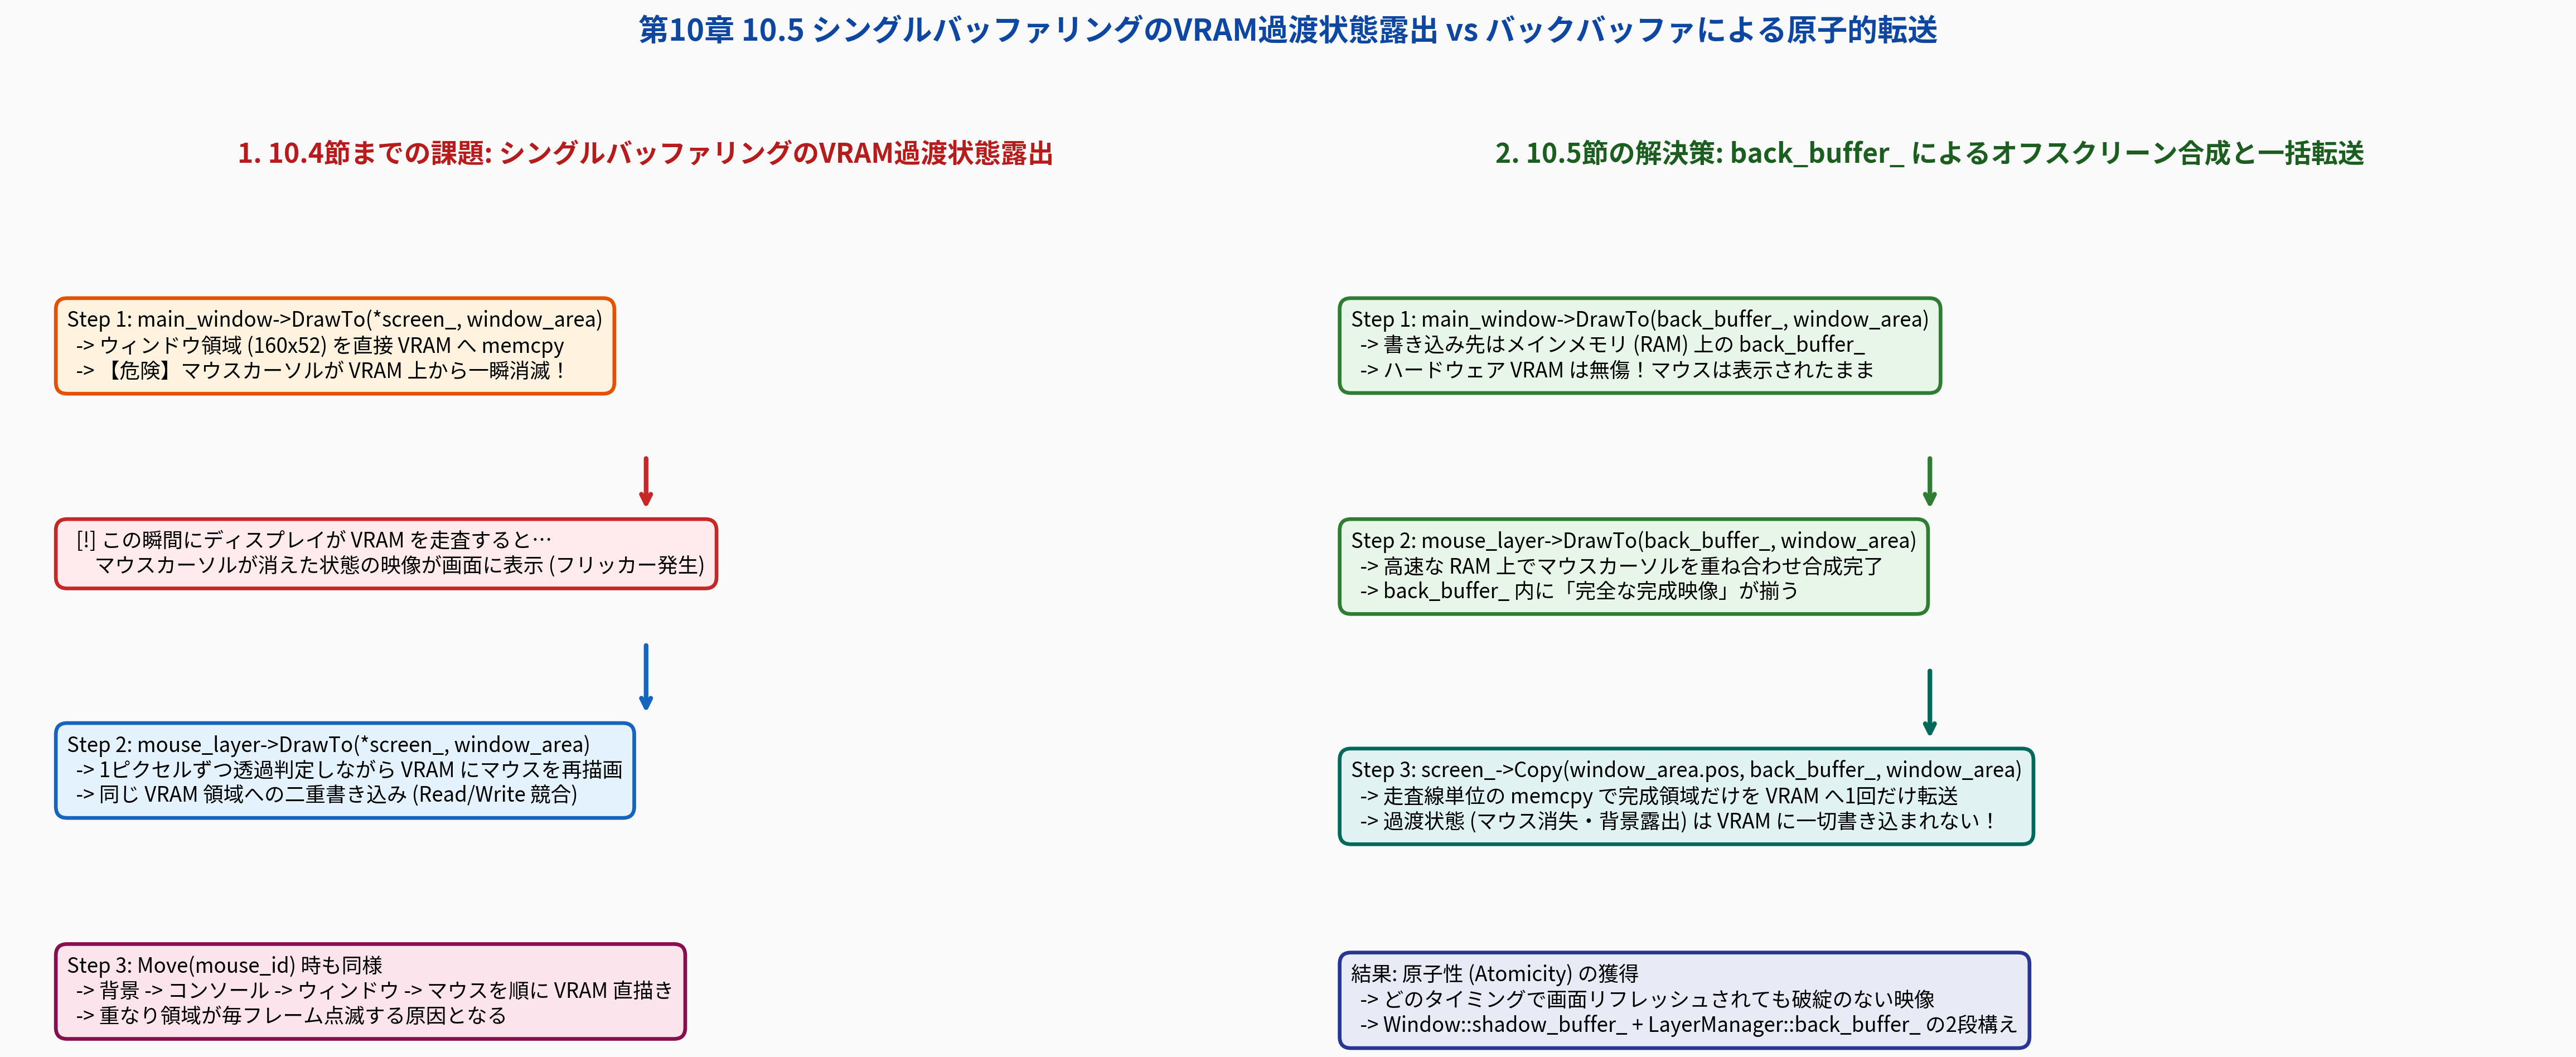

In [2]:
# 図版 10.13: シングルバッファリングの VRAM 過渡状態露出 vs バックバッファによる原子的転送の生成と表示
from IPython.display import Image, display
from common import generate_ch10_13_single_vs_double_buffering_pipeline

fig_path = generate_ch10_13_single_vs_double_buffering_pipeline(
    "10/result/fig10_13_single_vs_double_buffering_pipeline.png"
    if Path("10/result").parent.exists() and Path("common").exists()
    else "result/fig10_13_single_vs_double_buffering_pipeline.png"
)
print(f"Generated: {fig_path}")
display(Image(filename=str(fig_path)))

---

## 2. ダブルバッファリングの原理と2段階オフスクリーンバッファ構造

MikanOS では、第9.5節で導入した `Window::shadow_buffer_` に加え、本節で `LayerManager::back_buffer_` を導入することで、**役割の異なる 2 段階のオフスクリーンバッファ**が協調動作します。

| バッファ名 | 所属クラス | サイズ | 確保タイミング | 保護する対象（何を隠蔽するか） |
|---|---|---|---|---|
| **`shadow_buffer_`** | `Window`（不透過ウィンドウごと） | 各ウィンドウ幅 × 高さ (例: `160×52` = 32.5 KiB) | `Window` コンストラクタ | 単一ウィンドウ内の描画途中状態（`FillRectangle` 背景消去 → `WriteString` 文字描画）とライン一括コピー高速化 |
| **`back_buffer_`** | `LayerManager`（システム全体で1つ） | 画面全体幅 × 高さ (例: `1024×768` = 3.00 MiB) | `LayerManager::SetWriter` | 複数レイヤ間の重ね合わせ合成途中の状態（下層による上層の一時上書き、マウス点滅、`Move` 時の背景露出） |

---

### `FrameBuffer::Config()` と RAM 自動確保の仕組み

`back_buffer_` は特別な新規クラスを作らず、既存の `FrameBuffer` クラスをそのまま再利用します。そのために追加されたのが `kernel/frame_buffer.hpp` のわずか 1 行のゲッタです：

```cpp
class FrameBuffer {
 public:
  Error Initialize(const FrameBufferConfig& config);
  Error Copy(Vector2D<int> dst_pos, const FrameBuffer& src, const Rectangle<int>& src_area);
  void Move(Vector2D<int> dst_pos, const Rectangle<int>& src);

  FrameBufferWriter& Writer() { return *writer_; }
  const FrameBufferConfig& Config() const { return config_; } // ★ osbook_day10e で追加
```

`LayerManager::SetWriter(FrameBuffer* screen)` は、`screen->Config()` を値コピーしたうえで **`back_config.frame_buffer = nullptr` に書き換えて** `back_buffer_.Initialize(back_config)` を呼び出します：

```cpp
void LayerManager::SetWriter(FrameBuffer* screen) {
  screen_ = screen;

  FrameBufferConfig back_config = screen->Config();
  back_config.frame_buffer = nullptr;
  back_buffer_.Initialize(back_config);
}
```

### 空間計算量と走査線ストライド（Scanline Stride）正規化の数理

`FrameBuffer::Initialize` は `config_.frame_buffer == nullptr` を検出すると、次のように動作します：

1. **必要メモリ量の計算**:
   1ピクセルあたりのバイト数 $B_{	ext{bpp}} = 4\ 	ext{bytes}$（32-bit RGB/BGRX）のとき、バックバッファの総バイト数 $M_{	ext{back}}$ は：
   $$M_{	ext{back}} = B_{	ext{bpp}} 	imes W 	imes H$$
   標準解像度 $1024 	imes 768$ では：
   $$M_{	ext{back}} = 4 	imes 1024 	imes 768 = 3,145,728\ 	ext{bytes} = 3,072\ 	ext{KiB} = 3.00\ 	ext{MiB}$$
   第9.2節でカーネルヒープ（`InitializeHeap` により 128 MiB）を確保済みであるため、`std::vector<uint8_t> buffer_` によって即座に確保できます。

2. **走査線ストライドパディングの吸収**:
   実機の UEFI GOP フレームバッファ（`screen_`）では、GPU のメモリアライメント制約により `pixels_per_scan_line` ($S_{	ext{hw}}$) が水平解像度 $W$ より大きい（例: $W = 1024$ に対し $S_{	ext{hw}} = 1088$）場合があります。
   一方、`back_buffer_` は純粋な RAM 配列であるため、パディング不要で $S_{	ext{back}} = W$ に正規化されます：
   $$A_{	ext{vram}}(x, y) = 	ext{base}_{	ext{vram}} + 4 \cdot (S_{	ext{hw}} \cdot y + x)$$
   $$A_{	ext{back}}(x, y) = 	ext{base}_{	ext{back}} + 4 \cdot (W \cdot y + x)$$
   `FrameBuffer::Copy` はコピー元とコピー先それぞれの `BytesPerScanLine(config_)` を独立に計算して走査線を進行させるため、**ストライドが異なる VRAM と RAM 間の転送も一切の歪みなく安全に行われます**。

Generated: result/fig10_14_layermanager_back_buffer_architecture.png


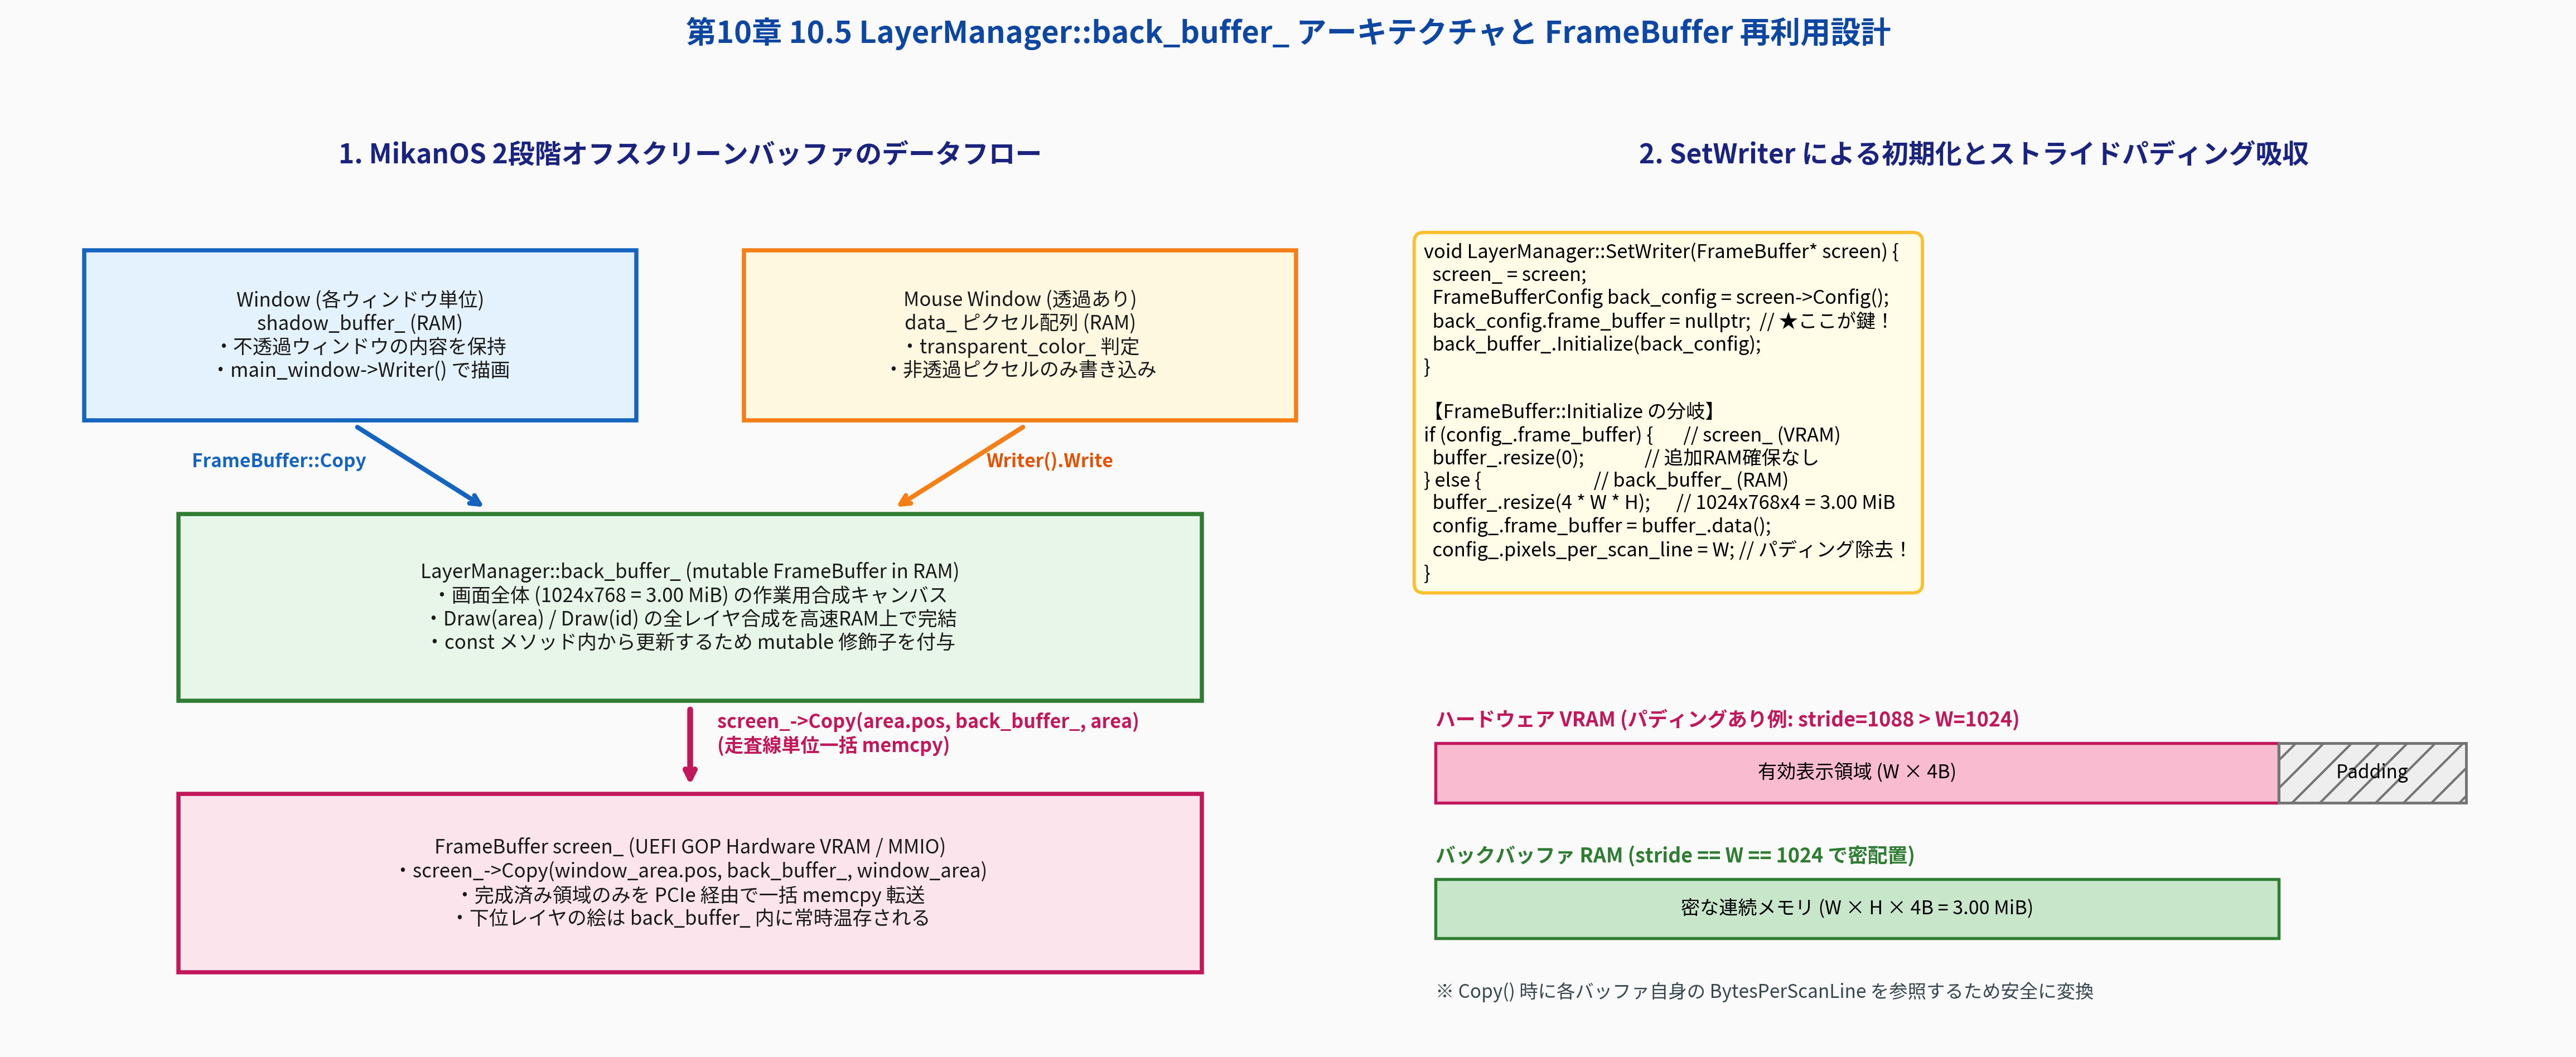

In [3]:
# 図版 10.14: LayerManager::back_buffer_ アーキテクチャと FrameBuffer 再利用設計の生成と表示
from common import generate_ch10_14_layermanager_back_buffer_architecture

fig_path = generate_ch10_14_layermanager_back_buffer_architecture(
    "10/result/fig10_14_layermanager_back_buffer_architecture.png"
    if Path("10/result").parent.exists() and Path("common").exists()
    else "result/fig10_14_layermanager_back_buffer_architecture.png"
)
print(f"Generated: {fig_path}")
display(Image(filename=str(fig_path)))

---

## 3. `LayerManager` への `back_buffer_` 組み込みと `osbook_day10e` 全差分コード解剖

公式リポジトリ `uchan-nos/mikanos` における `osbook_day10d` $	o$ `osbook_day10e` の実装変更は極めて簡潔でありながら、設計上の重要な C++ イディオムとグラフィックス上の不変条件を含んでいます。

### ① `kernel/layer.hpp`: `mutable FrameBuffer back_buffer_{};`

```cpp
 private:
  FrameBuffer* screen_{nullptr};
  mutable FrameBuffer back_buffer_{}; // ★ const メソッド Draw() から書き換えるため mutable！
  std::vector<std::unique_ptr<Layer>> layers_{};
  std::vector<Layer*> layer_stack_{};
  unsigned int latest_id_{0};
```

#### なぜ `mutable` 修飾子が必要なのか？
- `LayerManager::Draw(const Rectangle<int>& area) const` および `Draw(unsigned int id) const` は、いずれも **`const` メンバ関数**として宣言されています。
- オブジェクト指向設計において、`Draw` は「どのレイヤがどこにあり、どの z-order で並んでいるか」という **`LayerManager` の論理的状態（Logical State）を一切変更しない** ため、`const` であるべきです。
- 一方、`back_buffer_` は描画処理を高速化・無チラつき化するための**内部作業用キャッシュ／作業領域（Implementation Detail）**であり、外部から見た `LayerManager` の論理状態ではありません。
- このような**「論理的 const 性（Logical Constness）と物理的 const 性（Bitwise Constness）のギャップ」**を埋めるために C++ 標準が用意しているのが `mutable` キーワードです。

---

### ② `kernel/layer.cpp`: `Draw(area)` と `Draw(id)` の書き換え

```cpp
void LayerManager::Draw(const Rectangle<int>& area) const {
  for (auto layer : layer_stack_) {
    layer->DrawTo(back_buffer_, area);
  }
  screen_->Copy(area.pos, back_buffer_, area);
}

void LayerManager::Draw(unsigned int id) const {
  bool draw = false;
  Rectangle<int> window_area;
  for (auto layer : layer_stack_) {
    if (layer->ID() == id) {
      window_area.size = layer->GetWindow()->Size();
      window_area.pos = layer->GetPosition();
      draw = true;
    }
    if (draw) {
      layer->DrawTo(back_buffer_, window_area);
    }
  }
  screen_->Copy(window_area.pos, back_buffer_, window_area);
}
```

### 設計上の 2 つの重要ポイント（落とし穴の回避）

1. **なぜ `Draw(id)` で下位レイヤを描かなくても `back_buffer_` の絵が壊れないのか？**
   - `KernelMainNewStack` 起動時の最初の `layer_manager->Draw({{0, 0}, screen_size});` によって、`back_buffer_` 全体にはすでに背景（`DesktopBG`）とコンソール（`Console`）が描かれています。
   - 以降、どのレイヤ更新・移動もすべて `back_buffer_` に対して行われるため、**`back_buffer_` は常に直前フレームの完成画像（Persistent Offscreen Canvas）を保持**しています。
   - そのため、`Draw(id)` で下位レイヤをスキップしても、`back_buffer_` 上の `window_area` には過去の正しい背景が残っており、その上に `id` 以降（例: `main_window` $	o$ `mouse`）を上書きするだけで完全な合成結果が得られます。
2. **なぜ `screen_->Copy({0, 0}, back_buffer_, full_screen)` にしないのか？**
   - もし毎フレーム画面全体（1024×768 = 3.00 MiB）を VRAM にコピーすると、第10.3節と同様に PCIe バス帯域を浪費し、カウンタの更新速度が大きく低下します。
   - `screen_->Copy(window_area.pos, back_buffer_, window_area)` と**変更された矩形領域だけを切り出して一括転送**することで、転送量を **32.5 KiB（1/96）** に抑えたまま、完全なダブルバッファリングの原子性を両立しています！

---

### ③ `kernel/main.cpp` の変化は？
驚異的なことに、**`kernel/main.cpp`・`kernel/window.cpp`・`kernel/console.cpp` のロジックは 1 行も変更する必要がありません**（`osbook_day10e` の差分では書籍用範囲コメント `#@@range_begin` の削除のみ）。呼び出し側が一切意識することなく、`LayerManager` のカプセル化によってシステム全体のフリッカーが解消されます。

In [4]:
# 対話型 Python 実験 1: BackBufferConfigSim による FrameBuffer::Initialize モード切替とストライド吸収検証
from common import BackBufferConfigSim

# ハードウェア VRAM がパディング付きストライド (1088 px > 1024 px) を持つケースを想定
screen_cfg, back_cfg = BackBufferConfigSim.create_back_config_from_screen(
    screen_width=1024,
    screen_height=768,
    screen_stride=1088,
)

print("=== 1. Hardware VRAM (screen_) 設定 ===")
print(f"  モード                  : {screen_cfg.mode}")
print(f"  解像度                  : {screen_cfg.horizontal_resolution} x {screen_cfg.vertical_resolution}")
print(f"  有効ストライド          : {screen_cfg.effective_pixels_per_scan_line} px ({screen_cfg.scan_line_bytes:,} bytes/line)")
print(f"  追加 RAM 確保量         : {screen_cfg.allocated_ram_bytes:,} bytes (owns_memory={screen_cfg.owns_memory})")

print("\n=== 2. Offscreen BackBuffer (back_buffer_) 設定 ===")
print(f"  モード                  : {back_cfg.mode}")
print(f"  解像度                  : {back_cfg.horizontal_resolution} x {back_cfg.vertical_resolution}")
print(f"  正規化後ストライド      : {back_cfg.effective_pixels_per_scan_line} px ({back_cfg.scan_line_bytes:,} bytes/line)")
print(f"  自動確保 RAM 容量       : {back_cfg.allocated_ram_bytes:,} bytes ({back_cfg.allocated_ram_bytes / (1024**2):.2f} MiB)")

assert screen_cfg.allocated_ram_bytes == 0
assert back_cfg.allocated_ram_bytes == 1024 * 768 * 4
assert back_cfg.effective_pixels_per_scan_line == 1024
print("\n✅ ストライドパディング吸収と 3.00 MiB RAM バックバッファ確保を検証しました。")

=== 1. Hardware VRAM (screen_) 設定 ===
  モード                  : external_vram
  解像度                  : 1024 x 768
  有効ストライド          : 1088 px (4,352 bytes/line)
  追加 RAM 確保量         : 0 bytes (owns_memory=False)

=== 2. Offscreen BackBuffer (back_buffer_) 設定 ===
  モード                  : internal_back_buffer
  解像度                  : 1024 x 768
  正規化後ストライド      : 1024 px (4,096 bytes/line)
  自動確保 RAM 容量       : 3,145,728 bytes (3.00 MiB)

✅ ストライドパディング吸収と 3.00 MiB RAM バックバッファ確保を検証しました。


---

## 4. 対話型実験による VRAM 過渡状態・マウス重なりフリッカー完全解消の実証

実際のピクセル配列（NumPy バッファ）を用いて、**10.4節（シングルバッファリング）** と **10.5節（ダブルバッファリング）** の挙動をピクセル単位で比較します。

次の実験では、カウンタウィンドウ `[100..220, 60..110)` の上にマウスカーソル `[130..142, 75..91)` が重なっている状態で：
1. **`Draw(main_window)`（カウンタ更新時）** における VRAM 上の過渡的ピクセル破壊回数（`vram_transient_exposures`）
2. **`Move(mouse_layer)`（マウス移動時）** における VRAM 上の過渡的ピクセル破壊回数
3. 最終的な画面表示 `vram` と `back_buffer` の全ピクセル完全一致

を定量検証します。

In [5]:
# 対話型 Python 実験 2: DoubleBufferingLayerSim による VRAM 過渡状態露出のピクセル単位検証
import numpy as np
from common import DoubleBufferLayerSpec, DoubleBufferingLayerSim, SimRect

def make_solid(w: int, h: int, rgb: tuple[int, int, int]) -> np.ndarray:
    arr = np.empty((h, w, 3), dtype=np.uint8)
    arr[:, :] = rgb
    return arr

def setup_sim() -> DoubleBufferingLayerSim:
    sim = DoubleBufferingLayerSim(screen_w=320, screen_h=200)
    mouse_trans = (0, 0, 1)
    mouse_px = make_solid(12, 16, mouse_trans)
    mouse_px[2:12, 2:10] = (255, 255, 255)  # 白いマウス本体

    sim.add_layer(DoubleBufferLayerSpec(0, "DesktopBG", 0, 0, 320, 200, make_solid(320, 200, (45, 110, 142))))
    sim.add_layer(DoubleBufferLayerSpec(1, "Console", 0, 0, 180, 100, make_solid(180, 100, (16, 24, 32))))
    sim.add_layer(DoubleBufferLayerSpec(2, "MainWindow", 100, 60, 120, 50, make_solid(120, 50, (198, 198, 198))))
    sim.add_layer(DoubleBufferLayerSpec(3, "MouseCursor", 130, 75, 12, 16, mouse_px, transparent_color=mouse_trans))
    return sim

# 1. シングルバッファ (10.4) vs ダブルバッファ (10.5) での Draw(MainWindow)
sim_single = setup_sim()
sim_single.draw_area(SimRect(0, 0, 320, 200), use_double_buffer=True)  # 初期状態
res_draw_single = sim_single.draw_layer(2, use_double_buffer=False)

sim_double = setup_sim()
sim_double.draw_area(SimRect(0, 0, 320, 200), use_double_buffer=True)  # 初期状態
res_draw_double = sim_double.draw_layer(2, use_double_buffer=True)

print("=== 実験 A: カウンタウィンドウ更新 Draw(MainWindow) [マウス重なりあり] ===")
print(f"  [10.4 シングルバッファ] VRAM 過渡誤表示ピクセル延べ数 : {res_draw_single['vram_transient_exposures']} px")
print(f"  [10.5 ダブルバッファ]   VRAM 過渡誤表示ピクセル延べ数 : {res_draw_double['vram_transient_exposures']} px")
print(f"  [10.5 ダブルバッファ]   RAM 合成書込: {res_draw_double['ram_pixel_writes']} px -> VRAM 一括転送: {res_draw_double['vram_pixel_writes']} px")

# 2. Move(MouseCursor) での比較
res_move_single = sim_single.move_layer(3, new_x=150, new_y=80, use_double_buffer=False)
res_move_double = sim_double.move_layer(3, new_x=150, new_y=80, use_double_buffer=True)

print("\n=== 実験 B: マウス移動 Move(MouseCursor) ===")
print(f"  [10.4 シングルバッファ] VRAM 過渡誤表示ピクセル延べ数 : {res_move_single['vram_transient_exposures']} px")
print(f"  [10.5 ダブルバッファ]   VRAM 過渡誤表示ピクセル延べ数 : {res_move_double['vram_transient_exposures']} px")

assert res_draw_single["vram_transient_exposures"] > 0
assert res_draw_double["vram_transient_exposures"] == 0
assert res_move_single["vram_transient_exposures"] > 0
assert res_move_double["vram_transient_exposures"] == 0
assert np.array_equal(sim_double.vram, sim_double.back_buffer)
print("\n✅ ダブルバッファリングにより全操作で VRAM 過渡露出が 0 になることを実証しました！")

=== 実験 A: カウンタウィンドウ更新 Draw(MainWindow) [マウス重なりあり] ===
  [10.4 シングルバッファ] VRAM 過渡誤表示ピクセル延べ数 : 80 px
  [10.5 ダブルバッファ]   VRAM 過渡誤表示ピクセル延べ数 : 0 px
  [10.5 ダブルバッファ]   RAM 合成書込: 6080 px -> VRAM 一括転送: 6000 px

=== 実験 B: マウス移動 Move(MouseCursor) ===
  [10.4 シングルバッファ] VRAM 過渡誤表示ピクセル延べ数 : 384 px
  [10.5 ダブルバッファ]   VRAM 過渡誤表示ピクセル延べ数 : 0 px

✅ ダブルバッファリングにより全操作で VRAM 過渡露出が 0 になることを実証しました！


---

## 5. ハードウェアメモリ階層（RAM vs PCIe MMIO VRAM）と性能・限界の定量解析

バックバッファの導入は「チラつきの解消」だけでなく、**x86-64 PC ハードウェアのメモリアーキテクチャ特性**にも極めて合理的に適合しています。

### 1. メモリアクセス特性の決定的違い
- **システム RAM (`back_buffer_`)**:
  - CPU 直結の DDR メモリコントローラ経由でアクセスされ、**L1/L2/L3 CPU キャッシュ（Write-Back キャッシング）**が最大限に機能します。
  - ランダムアクセス（マウスカーソルの 1 ピクセルずつの透過判定描画 `Writer().Write`）や重複上書きが発生しても、CPU キャッシュ内で超高速に吸収されます。
- **ハードウェア VRAM (`screen_`)**:
  - PCIe バス経由の MMIO（Memory-Mapped I/O）空間に配置されており、通常は **WC（Write-Combining）** または **UC（Uncacheable）** 属性でマップされています。
  - 1 ピクセルずつの散発的書き込みや Read-Modify-Write は非常に遅い一方、**`memcpy` による連続シーケンシャル書き込みは WC バッファによりバースト転送され、最大効率を発揮**します。
  - MikanOS のダブルバッファリングは、**「複雑な合成（ランダム・多層重ね描き）はキャッシュの効く RAM 上の `back_buffer_` で行い、PCIe 越しの VRAM には `screen_->Copy` による連続シーケンシャル `memcpy` だけを送る」** という、ハードウェア特性に完璧に合致した設計となっています。

### 2. 第10.3節 $	o$ 10.4節 $	o$ 10.5節 の進化まとめ

| 項目 | 10.3 全画面再描画 (`day10c`) | 10.4 限定再描画 `Draw(id)` (`day10d`) | 10.5 バックバッファ (`day10e`) |
|---|---|---|---|
| **VRAM 転送量 / フレーム** | 約 4,105.9 KiB (4.01 MiB) | 約 33.9 KiB (窓 + マウス散発) | **32.5 KiB (窓領域のみ一括)** |
| **VRAM 上の過渡露出** | 極大 (背景から全レイヤ点滅) | 中 (マウス重複・`Move` 時に点滅) | **ゼロ (完成画像のみ転送)** |
| **追加メモリコスト** | 0 MiB | 0 MiB | **3.00 MiB (1024×768×4B)** |
| **VRAM への書込回数/px** | 最大 4 回 (重複上書き) | 最大 2 回 (窓＋マウス) | **厳密に 1 回 (`Copy` のみ)** |

### 3. 補足: ダブルバッファリングでも残る「垂直同期 (VSync) とティアリング」
本節で**同一ピクセルへの上書きによる「フリッカー（点滅）」は完全にゼロ**になりました。なお、ハードウェアの垂直帰線期間（*VBlank / VSync*）と非同期に `screen_->Copy` を行うため、理論上は「高速移動するウィンドウの上半分と下半分が別フレームになる **ティアリング（Tearing）**」は起き得ますが、160×52 のような小領域の `memcpy` はマイクロ秒オーダーで完了するため実用上ほとんど目立ちません（現代 OS のコンポジタでは VSync 割り込みに同期したページフリップを行います）。

Generated: result/fig10_15_flicker_elimination_vram_atomicity_analysis.png


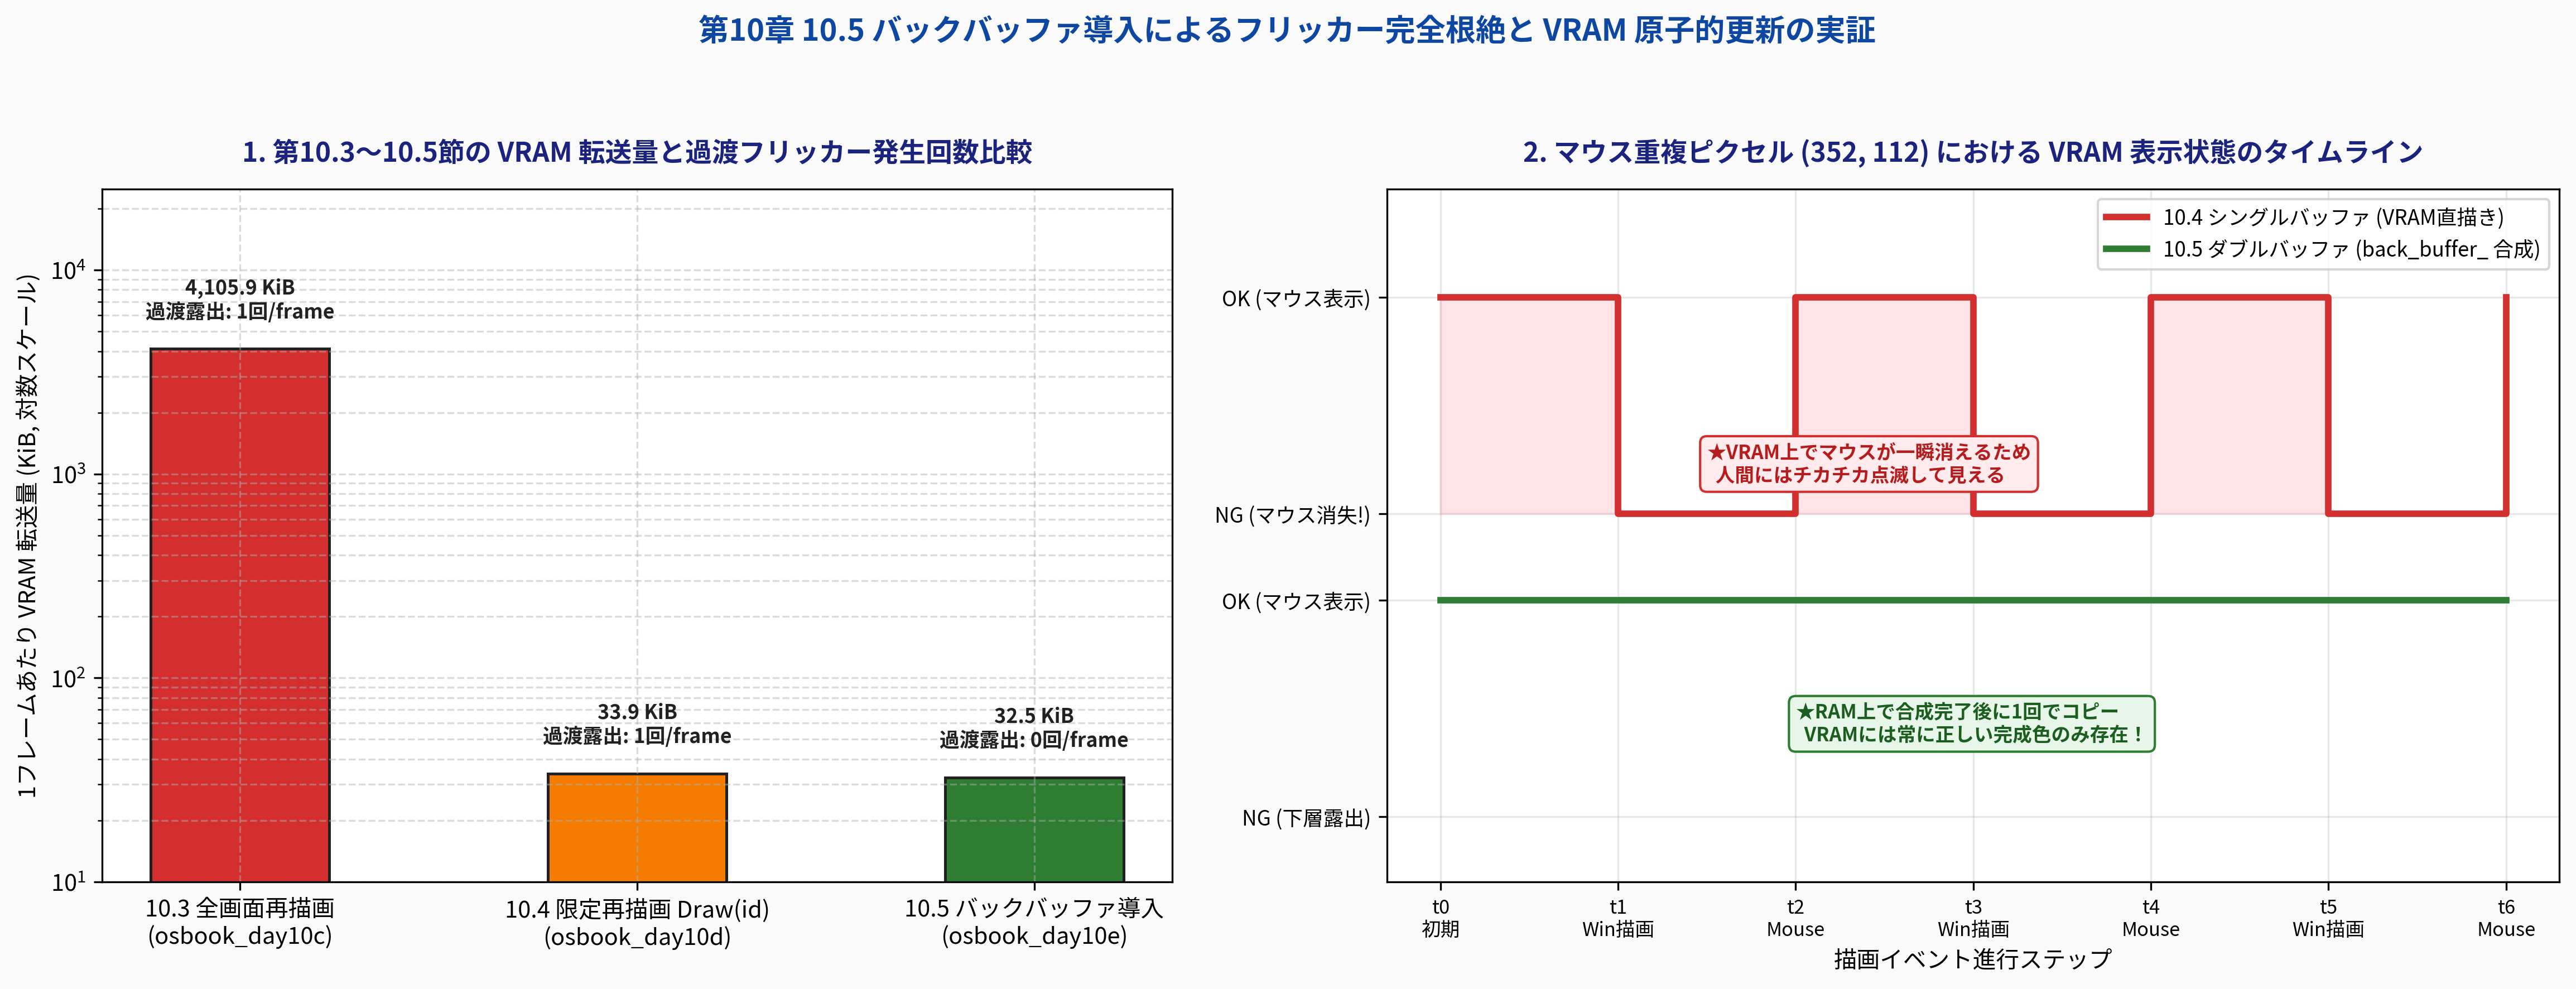

In [6]:
# 図版 10.15: 第10.3〜10.5節の VRAM 転送量比較とマウス重複ピクセル状態タイムラインの生成と表示
from common import generate_ch10_15_flicker_elimination_vram_atomicity_analysis

fig_path = generate_ch10_15_flicker_elimination_vram_atomicity_analysis(
    "10/result/fig10_15_flicker_elimination_vram_atomicity_analysis.png"
    if Path("10/result").parent.exists() and Path("common").exists()
    else "result/fig10_15_flicker_elimination_vram_atomicity_analysis.png"
)
print(f"Generated: {fig_path}")
display(Image(filename=str(fig_path)))

---

## 6. C++20 単体検証プログラムと CMake ターゲット

本節で解説した `FrameBuffer::Config()`、`back_config.frame_buffer = nullptr` による内部 RAM バッファ確保、ストライドパディングの吸収、`mutable FrameBuffer back_buffer_{}` を用いた `LayerManager::Draw(area)` / `Draw(id)` / `Move` の全機能は、スタンドアロン C++20 プログラム（`src/ch10/os_chapter10_double_buffering.cpp`）に実装され、CMake ターゲット `ch10_double_buffering` として検証されています。

### C++20 検証プログラムのテスト項目
1. **パディング付きハードウェアストライド (`384 px > 320 px`) の吸収検証**:
   - `screen` の `pixels_per_scan_line == 384` に対し、`back_buffer_` は `pixels_per_scan_line == 320` で密に RAM 確保（`256,000 bytes`）されることを `assert`。
2. **シングルバッファ vs ダブルバッファの過渡露出比較**:
   - マウスカーソルとウィンドウが重なる座標 `(132, 77)` をプローブし、旧方式では `single_exposures == 1` の誤表示が発生する一方、新方式では `0` であることを検証。
3. **部分転送量の定量検証**:
   - `Draw(main_id)` で VRAM に転送されるピクセル数がウィンドウ面積 `120 × 50 = 6,000 px`（`24,000 bytes`）のみであることを検証。
4. **画面端クリッピング付き `Move` と全ピクセル完全一致**:
   - マウスを画面右端 `(315, 190)` へ移動した後の `screen`（VRAM）全ピクセルが `back_buffer_`（RAM）と 1 ピクセルの誤差なく一致することを検証。

In [7]:
# C++20 スタンドアロン検証プログラムの実行
import subprocess
from pathlib import Path

binary_path = Path("build/bin/ch10_double_buffering")
if not binary_path.exists():
    binary_path = Path("../build/bin/ch10_double_buffering")

if not binary_path.exists():
    print("CMake ビルドを実行中...")
    build_dir = Path("build") if Path("build").exists() else Path("../build")
    subprocess.run(["cmake", "--build", str(build_dir), "--target", "ch10_double_buffering"], check=True)

result = subprocess.run([str(binary_path)], capture_output=True, text=True, check=True)
print(result.stdout)

=== Chapter 10.5 Double Buffering & Back Buffer Verification ===
VRAM Stride (padded): 384 px | BackBuffer Stride (compact): 320 px
BackBuffer RAM Size: 256000 bytes
Single-Buffer Draw(main_id) VRAM transient mouse flicker exposures: 1
Double-Buffer Draw(main_id) VRAM transient flicker exposures: 0
Partial Atomic Copy Pixels on Draw(main_id): 6000 px (24000 bytes)
All C++20 Chapter 10.5 Assertions PASSED Successfully!



---

## 7. まとめと第10章 10.6 への展望

### 本節で達成した成果
1. **バックバッファ（ダブルバッファリング）の導入**:
   - `FrameBuffer::Config()` を追加し、`LayerManager::SetWriter` で `back_config.frame_buffer = nullptr` を渡すことで、既存の `FrameBuffer` クラスをそのまま RAM 上のオフスクリーンバッファとして再利用しました。
2. **`mutable FrameBuffer back_buffer_{}` によるクリーンなカプセル化**:
   - `Draw(area) const` と `Draw(id) const` の論理的 const 性を保ったまま、`back_buffer_` 上で全レイヤ合成を完了し、`screen_->Copy` によって完成済み領域だけを VRAM へ原子的転送しました。
3. **マウス重なりフリッカー・`Move` 過渡ちらつきの完全根絶**:
   - シングルバッファリングで避けられなかった VRAM 上の中間上書き（マウス消失・背景露出）を物理的にゼロ化し、現代的な GUI デスクトップの描画品質を達成しました。

---

### 次節への道: 10.6 ウィンドウのドラッグ移動 (`osbook_day10f`)
チラつきのない安定したウィンドウと高速な部分再描画基盤が整った今、いよいよ GUI OS らしいインタラクションへと進みます。
次節 **10.6「ウィンドウのドラッグ移動 (`osbook_day10f`)」** では：
- マウス左ボタンの押下状態（`buttons` ビットフィールド）の検出
- マウスカーソルの先端座標にある最前面ウィンドウを探索する **`LayerManager::FindLayerByPosition`** の設計
- マウスの移動差分（`dx, dy`）に追従してウィンドウを滑らかにドラッグ移動させるイベント処理

を実装し、静止していたウィンドウを自在に動かせるようにします！